# 06 · Delivery-Time Model: Route-Level Promises

**Business problem** (from notebook 04): Olist promises ~24 days for a delivery that takes ~12.
Early delivery earns no rating credit, and cutting every promise uniformly backfires
(3 days shorter → late rate 6.8% → 11.3%). The answer is a **promise per order**, short where the
route is reliable and long where it is risky.

**Approach**
- Predict delivery time **at purchase**, using only information available then (product, basket, route, distance,
  seller and route track record from *earlier* orders). Leakage is tested in `tests/test_features.py`.
- **Quantile regression** (LightGBM, 10 quantiles): a promise at the P90 quantile is kept ~90% of the time.
  Each quantile is a candidate policy; the business picks the trade-off.
- **Time-based split:** train Jan 2017 – Apr 2018, choose the policy on May 2018, report once on Jun – Aug 2018.

Code: [`src/ecom/models/delivery_time.py`](../src/ecom/models/delivery_time.py)

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecom import viz
from ecom.features import build_features

warnings.filterwarnings("ignore", category=UserWarning)
viz.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
features = build_features()  # leakage-safe, see src/ecom/features.py

In [ ]:
from ecom.models import delivery_time

model, metrics, curve = delivery_time.train(features)
pd.Series(metrics["test_mae_days"], name="test MAE (days)").to_frame()

,test MAE (days)
lightgbm_p50,3.441
route_history_90d,4.697
train_median,4.896


The median model is **~3.4 days** off on average, versus 4.7 for the best simple baseline (the route's recent average).
But the business decision isn't the median. It's how much buffer to add, so the full quantile curve matters more:

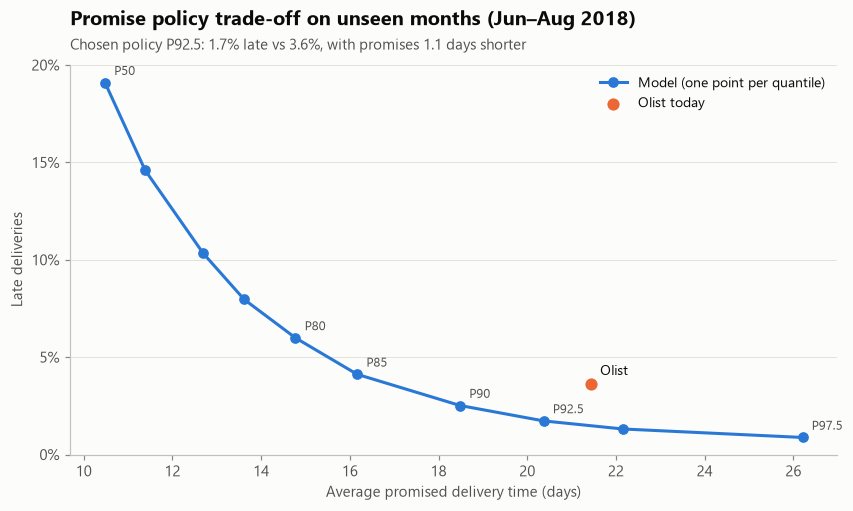

,policy,late_pct,avg_promise_days
11,Olist today,3.612,21.437
12,Model P50,19.094,10.479
13,Model P60,14.594,11.384
14,Model P70,10.326,12.695
15,Model P75,7.961,13.618
16,Model P80,5.988,14.774
17,Model P85,4.118,16.165
18,Model P90,2.516,18.485
19,Model P92.5,1.726,20.369
20,Model P95,1.312,22.154


In [ ]:
t = curve[curve["split"] == "test"]
olist = t[t["policy"] == "Olist today"].iloc[0]
m = t[t["quantile"].notna()]
chosen = m[m["quantile"] == model.chosen_quantile].iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(
    m["avg_promise_days"],
    m["late_pct"],
    color=viz.BLUE,
    marker="o",
    label="Model (one point per quantile)",
)
ax.scatter(
    olist["avg_promise_days"],
    olist["late_pct"],
    color=viz.ORANGE,
    s=90,
    zorder=3,
    edgecolor=viz.SURFACE,
    linewidth=1.5,
    label="Olist today",
)
for _, r in m.iterrows():
    if r["quantile"] in (0.5, 0.8, 0.85, 0.9, model.chosen_quantile, 0.975):
        ax.annotate(
            f"P{r['quantile'] * 100:g}",
            (r["avg_promise_days"], r["late_pct"]),
            xytext=(6, 5),
            textcoords="offset points",
            fontsize=8.5,
            color=viz.INK_2,
        )
ax.annotate(
    "Olist",
    (olist["avg_promise_days"], olist["late_pct"]),
    xytext=(6, 6),
    textcoords="offset points",
    fontsize=9,
    color=viz.INK,
)
ax.yaxis.set_major_formatter(viz.PCT)
ax.yaxis.set_major_locator(plt.MultipleLocator(5))
ax.set_xlabel("Average promised delivery time (days)")
ax.set_ylabel("Late deliveries")
ax.set_ylim(0)
ax.legend(loc="upper right")
ax.set_title("Promise policy trade-off on unseen months (Jun–Aug 2018)")
viz.subtitle(
    ax,
    f"Chosen policy P{model.chosen_quantile * 100:g}: {chosen['late_pct']:.1f}% late vs {olist['late_pct']:.1f}%, "
    f"with promises {olist['avg_promise_days'] - chosen['avg_promise_days']:.1f} days shorter",
)
viz.save(fig, "promise_policy_curve")
plt.show()

t[["policy", "late_pct", "avg_promise_days"]]

In [ ]:
def option(q):
    r = m[m["quantile"] == q].iloc[0]
    return pd.Series(
        {
            "late_pct": r["late_pct"],
            "late_vs_olist": f"{(r['late_pct'] / olist['late_pct'] - 1) * 100:+.0f}%",
            "promise_days": r["avg_promise_days"],
            "promise_vs_olist_days": f"{r['avg_promise_days'] - olist['avg_promise_days']:+.1f}",
        }
    )


pd.DataFrame(
    {
        f"Reliability: P{model.chosen_quantile * 100:g} (chosen on validation)": option(
            model.chosen_quantile
        ),
        "Balanced: P90": option(0.9),
        "Growth: P85": option(0.85),
    }
).T

,late_pct,late_vs_olist,promise_days,promise_vs_olist_days
Reliability: P92.5 (chosen on validation),1.726,-52%,20.369,-1.1
Balanced: P90,2.516,-30%,18.485,-3.0
Growth: P85,4.118,+14%,16.165,-5.3


The blue curve passes **below and to the left of Olist's point**: there are model policies that are late less often
*and* promise sooner. The quantile is a dial the business sets:

- **Reliability** (picked on validation as the shortest promise with a late rate no worse than Olist's): late deliveries
  roughly **halved**, with promises about a day *shorter*.
- **Balanced (P90):** fewer late orders *and* shorter promises at the same time.
- **Growth (P85):** about today's late rate with promises **~5 days shorter**, a conversion lever because a 16-day promise
  sells better than a 21-day one.

## Where the gain comes from: buffer allocated by risk

In [ ]:
df = delivery_time.modelling_frame(features)
te = df[df["split"] == "test"].copy()
te["model_promise"] = model.promise_days(te)
te["route_type"] = np.where(te["same_state"] == 1, "Same state", "Cross-state")
(
    te.groupby("route_type").agg(
        orders=("order_id", "size"),
        actual_days=("delivery_cal_days", "mean"),
        olist_promise=("olist_promise_days", "mean"),
        model_promise=("model_promise", "mean"),
        olist_late_pct=("is_late", lambda s: 100 * s.astype(float).mean()),
        model_late_pct=(
            "model_promise",
            lambda p: 100 * (te.loc[p.index, "delivery_cal_days"] > p).mean(),
        ),
    )
)

,orders,actual_days,olist_promise,model_promise,olist_late_pct,model_late_pct
route_type,,,,,,
Cross-state,11082,10.414,26.044,24.174,2.454,1.570
Same state,7521,5.824,14.649,14.763,5.318,1.955


Olist's buffer is **misallocated**: same-state orders are late about twice as often as cross-state ones,
so short routes are under-padded and long routes over-padded. The model sizes the buffer to each order's risk, so the late rate
is low and nearly equal on both route types. The same mechanism produces the shorter promises of the P85/P90 policies.

## What drives delivery time?

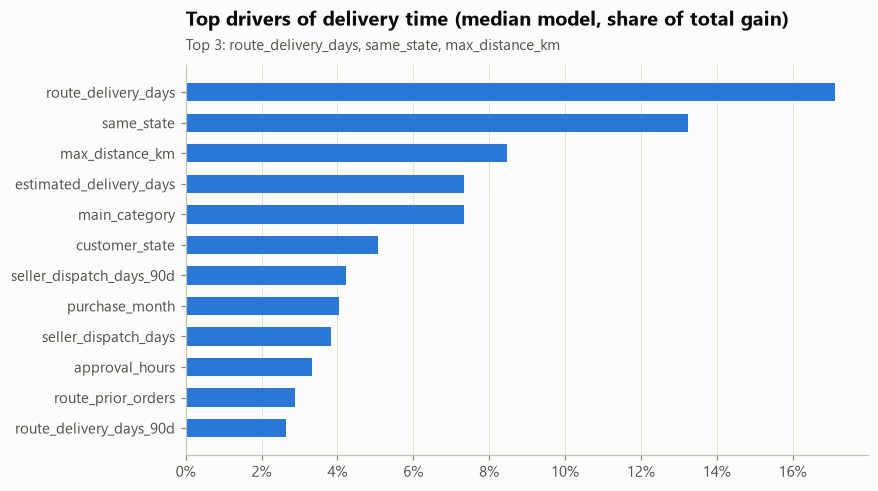

In [ ]:
m50 = model.models[0.5]
imp = (
    pd.Series(m50.booster_.feature_importance("gain"), index=model.features).sort_values().tail(12)
    / m50.booster_.feature_importance("gain").sum()
    * 100
)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(imp.index, imp.values, color=viz.BLUE, height=0.6)
ax.xaxis.set_major_formatter(viz.PCT)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Top drivers of delivery time (median model, share of total gain)")
top3 = ", ".join(imp.index[::-1][:3])
viz.subtitle(ax, f"Top 3: {top3}")
viz.save(fig, "delivery_feature_importance")
plt.show()

## Conclusions & next steps

1. A purchase-time quantile model **dominates Olist's flat promise**: there are policies with fewer late orders *and* shorter promises.
   The point model is ~3.4 days off on average vs 4.7 for the best simple baseline.
2. The quantile is a **business decision** (reliability vs conversion). A/B test it on conversion rate and negative-review rate.
3. **Drift:** test-period deliveries were faster than training-period ones (Olist improved logistics in 2018).
   The time-based split exposed this. In production, retrain monthly and monitor the realised late rate per quantile.